<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Data Visualization**


Estimated time needed: **45** minutes


In this lab, you will focus on data visualization. The dataset will be provided through an RDBMS, and you will need to use SQL queries to extract the required data.


## Objectives


After completing this lab, you will be able to:


-   Visualize the distribution of data.

-   Visualize the relationship between two features.

-   Visualize composition and comparison of data.




## Demo: How to work with database


Download the database file.


In [1]:
!wget https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv

--2026-09-23 03:20:21--  https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv
Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 159525875 (152M) [text/csv]
Saving to: ‘survey-data.csv.4’

survey-data.csv.4   100%[===================>] 152.13M  40.9MB/s    in 3.7s    
2026-09-23 03:20:29 (40.9 MB/s) - ‘survey-data.csv.4’ saved [159525875/159525875]


**Install and Import Necessary Python Libraries**

Ensure that you have the required libraries installed to work with SQLite and Pandas:


In [2]:
!pip install pandas 
!pip install matplotlib

import pandas as pd
import matplotlib.pyplot as plt

**Read the CSV File into a Pandas DataFrame**

Load the Stack Overflow survey data into a Pandas DataFrame:


In [3]:
# Read the CSV file
df = pd.read_csv('survey-data.csv')

# Display the first few rows of the data
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


**Create a SQLite Database and Insert the Data**

Now, let's create a new SQLite database (`survey-data.sqlite`) and insert the data from the DataFrame into a table using the sqlite3 library:


In [4]:
import sqlite3

# Create a connection to the SQLite database
conn = sqlite3.connect('survey-data.sqlite')

# Write the dataframe to the SQLite database
df.to_sql('main', conn, if_exists='replace', index=False)


# Close the connection
conn.close()

**Verify the Data in the SQLite Database**
Verify that the data has been correctly inserted into the SQLite database by running a simple query:


In [5]:
# Reconnect to the SQLite database
conn = sqlite3.connect('survey-data.sqlite')

# Run a simple query to check the data
QUERY = "SELECT * FROM main LIMIT 5"
df_check = pd.read_sql_query(QUERY, conn)

# Display the results
print(df_check)

   ResponseId                      MainBranch                 Age  \
0           1  I am a developer by profession  Under 18 years old   
1           2  I am a developer by profession     35-44 years old   
2           3  I am a developer by profession     45-54 years old   
3           4           I am learning to code     18-24 years old   
4           5  I am a developer by profession     18-24 years old   

            Employment RemoteWork   Check  \
0  Employed, full-time     Remote  Apples   
1  Employed, full-time     Remote  Apples   
2  Employed, full-time     Remote  Apples   
3   Student, full-time        NaN  Apples   
4   Student, full-time        NaN  Apples   

                                    CodingActivities  \
0                                              Hobby   
1  Hobby;Contribute to open-source projects;Other...   
2  Hobby;Contribute to open-source projects;Other...   
3                                                NaN   
4                                 

## Demo: Running an SQL Query


Count the number of rows in the table named 'main'


## Demo: Listing All Tables


To view the names of all tables in the database:


In [6]:
QUERY = """
SELECT name as Table_Name FROM sqlite_master 
WHERE type = 'table'
"""
pd.read_sql_query(QUERY, conn)

,Table_Name
0,main


## Demo: Running a Group By Query
    
For example, you can group data by a specific column, like Age, to get the count of respondents in each age group:


In [7]:
QUERY = """
SELECT Age, COUNT(*) as count
FROM main
GROUP BY Age
ORDER BY Age
"""
pd.read_sql_query(QUERY, conn)

,Age,count
0,18-24 years old,14098
1,25-34 years old,23911
2,35-44 years old,14942
3,45-54 years old,6249
4,55-64 years old,2575
5,65 years or older,772
6,Prefer not to say,322
7,Under 18 years old,2568


## Demo: Describing a table

Use this query to get the schema of a specific table, main in this case:


In [8]:
table_name = 'main'

QUERY = """
SELECT sql FROM sqlite_master 
WHERE name= '{}'
""".format(table_name)

df = pd.read_sql_query(QUERY, conn)
print(df.iat[0,0])

CREATE TABLE "main" (
"ResponseId" INTEGER,
  "MainBranch" TEXT,
  "Age" TEXT,
  "Employment" TEXT,
  "RemoteWork" TEXT,
  "Check" TEXT,
  "CodingActivities" TEXT,
  "EdLevel" TEXT,
  "LearnCode" TEXT,
  "LearnCodeOnline" TEXT,
  "TechDoc" TEXT,
  "YearsCode" TEXT,
  "YearsCodePro" TEXT,
  "DevType" TEXT,
  "OrgSize" TEXT,
  "PurchaseInfluence" TEXT,
  "BuyNewTool" TEXT,
  "BuildvsBuy" TEXT,
  "TechEndorse" TEXT,
  "Country" TEXT,
  "Currency" TEXT,
  "CompTotal" REAL,
  "LanguageHaveWorkedWith" TEXT,
  "LanguageWantToWorkWith" TEXT,
  "LanguageAdmired" TEXT,
  "DatabaseHaveWorkedWith" TEXT,
  "DatabaseWantToWorkWith" TEXT,
  "DatabaseAdmired" TEXT,
  "PlatformHaveWorkedWith" TEXT,
  "PlatformWantToWorkWith" TEXT,
  "PlatformAdmired" TEXT,
  "WebframeHaveWorkedWith" TEXT,
  "WebframeWantToWorkWith" TEXT,
  "WebframeAdmired" TEXT,
  "EmbeddedHaveWorkedWith" TEXT,
  "EmbeddedWantToWorkWith" TEXT,
  "EmbeddedAdmired" TEXT,
  "MiscTechHaveWorkedWith" TEXT,
  "MiscTechWantToWorkWith" TEXT,


## Hands-on Lab


### Visualizing the Distribution of Data

**Histograms**

Plot a histogram of CompTotal (Total Compensation).


In [15]:
print(df.columns.tolist())

['sql']

In [19]:
# Run this only if the code above fails to find the 'master' table
conn = sqlite3.connect('survey-results.sqlite')
print(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table';", conn))
conn.close()

Empty DataFrame
Columns: [name]
Index: []

<Axes: title={'center': 'Histogram of Total Compensation'}, ylabel='Frequency'>

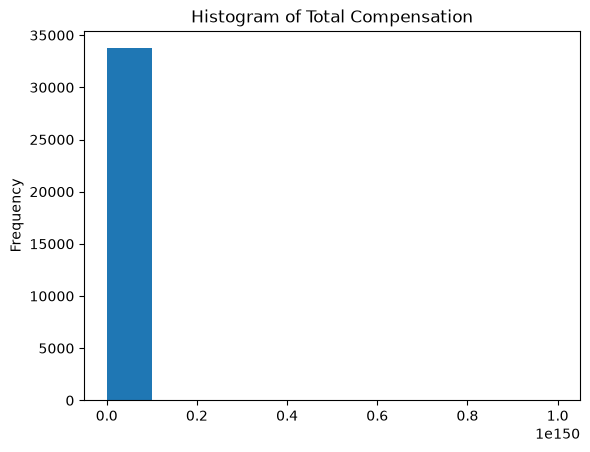

In [20]:
import pandas as pd

# 1. Load the data directly from the CSV file
df = pd.read_csv('survey-data.csv')

# 2. Strip any accidental whitespace from the column names
df.columns = df.columns.str.strip()

# 3. Plot the histogram
df['CompTotal'].plot(kind='hist', title='Histogram of Total Compensation')

**Box Plots**

Plot a box plot of Age.


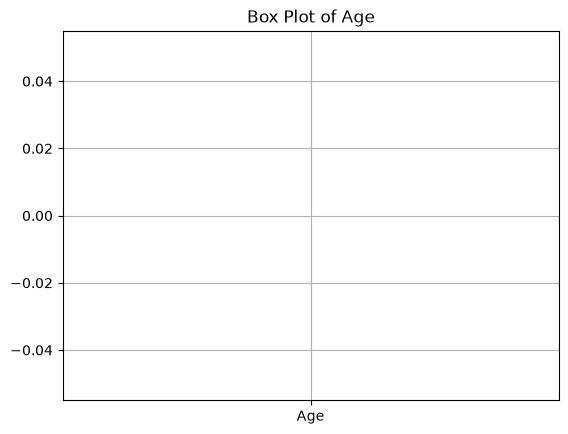

In [22]:
## Write your code here
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the data
df = pd.read_csv('survey-data.csv')
df.columns = df.columns.str.strip()

# 2. Force the 'Age' column to be numeric (converts any text/errors into missing numbers safely)
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')

# 3. Use the dedicated boxplot function
df.boxplot(column='Age')
plt.title('Box Plot of Age')
plt.show()

### Visualizing Relationships in Data

**Scatter Plots**

Create a scatter plot of Age and WorkExp.


<Axes: title={'center': 'Scatter Plot of Age and WorkExp'}, xlabel='Age', ylabel='WorkExp'>

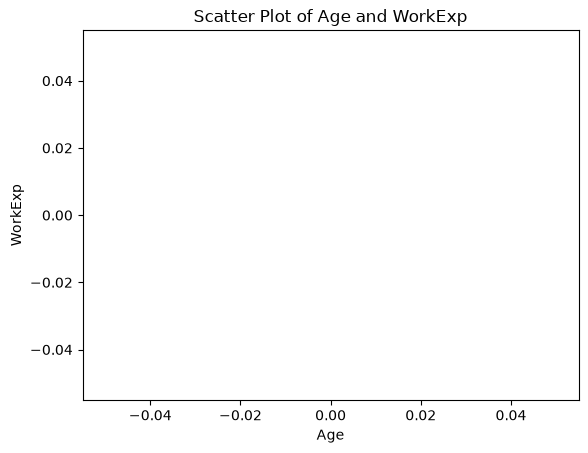

In [23]:
## Write your code here
import pandas as pd

# 1. Load the data from the CSV file
df = pd.read_csv('survey-data.csv')
df.columns = df.columns.str.strip()

# 2. Convert columns to numeric values to avoid type errors
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')
df['WorkExp'] = pd.to_numeric(df['WorkExp'], errors='coerce')

# 3. Create a scatter plot of Age and WorkExp
df.plot(kind='scatter', x='Age', y='WorkExp', title='Scatter Plot of Age and WorkExp')

**Bubble Plots**

Create a bubble plot of `TimeSearching` and `Frustration` using the Age column as the bubble size.


<Axes: title={'center': 'Bubble Plot'}, xlabel='TimeSearching', ylabel='Frustration'>

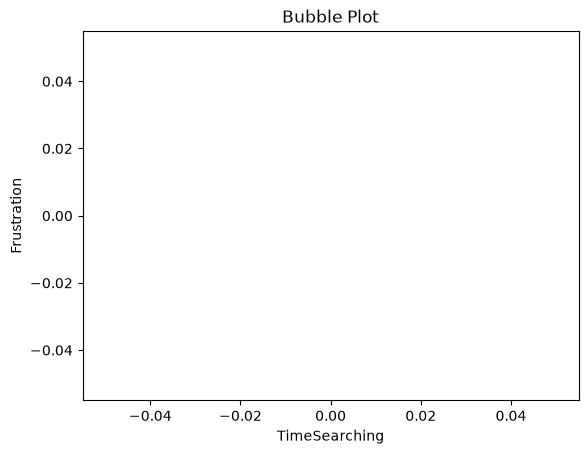

In [24]:
## Write your code here
import pandas as pd

# 1. Load the data directly from the CSV file
df = pd.read_csv('survey-data.csv')
df.columns = df.columns.str.strip()

# 2. Convert columns to numeric values and drop missing rows so the chart isn't empty
df['TimeSearching'] = pd.to_numeric(df['TimeSearching'], errors='coerce')
df['Frustration'] = pd.to_numeric(df['Frustration'], errors='coerce')
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')
df_clean = df.dropna(subset=['TimeSearching', 'Frustration', 'Age'])

# 3. Create a bubble plot using the Age column as the bubble size
df_clean.plot(kind='scatter', x='TimeSearching', y='Frustration', s=df_clean['Age'], title='Bubble Plot')

### Visualizing Composition of Data

**Pie Charts**

Create a pie chart of the top 5 databases(`DatabaseWantToWorkWith`) that respondents wish to learn next year.


In [27]:
import pandas as pd
df = pd.read_csv('survey-data.csv')
print(df.columns.tolist())

['ResponseId', 'MainBranch', 'Age', 'Employment', 'RemoteWork', 'Check', 'CodingActivities', 'EdLevel', 'LearnCode', 'LearnCodeOnline', 'TechDoc', 'YearsCode', 'YearsCodePro', 'DevType', 'OrgSize', 'PurchaseInfluence', 'BuyNewTool', 'BuildvsBuy', 'TechEndorse', 'Country', 'Currency', 'CompTotal', 'LanguageHaveWorkedWith', 'LanguageWantToWorkWith', 'LanguageAdmired', 'DatabaseHaveWorkedWith', 'DatabaseWantToWorkWith', 'DatabaseAdmired', 'PlatformHaveWorkedWith', 'PlatformWantToWorkWith', 'PlatformAdmired', 'WebframeHaveWorkedWith', 'WebframeWantToWorkWith', 'WebframeAdmired', 'EmbeddedHaveWorkedWith', 'EmbeddedWantToWorkWith', 'EmbeddedAdmired', 'MiscTechHaveWorkedWith', 'MiscTechWantToWorkWith', 'MiscTechAdmired', 'ToolsTechHaveWorkedWith', 'ToolsTechWantToWorkWith', 'ToolsTechAdmired', 'NEWCollabToolsHaveWorkedWith', 'NEWCollabToolsWantToWorkWith', 'NEWCollabToolsAdmired', 'OpSysPersonal use', 'OpSysProfessional use', 'OfficeStackAsyncHaveWorkedWith', 'OfficeStackAsyncWantToWorkWith',

<Axes: title={'center': 'Top 5 Databases to Learn Next Year'}>

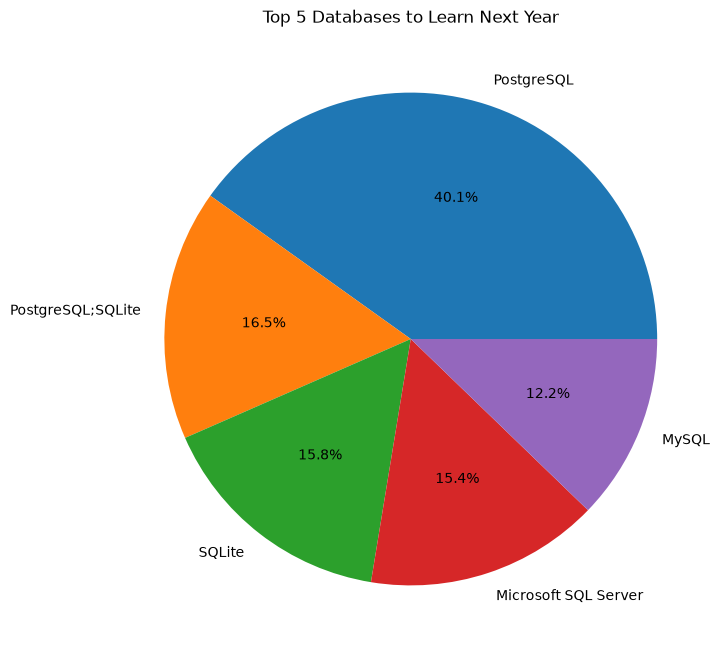

In [28]:
## Write your code here
import pandas as pd

# 1. Load the data from the CSV file
df = pd.read_csv('survey-data.csv')
df.columns = df.columns.str.strip()

# 2. Get the top 5 databases using the correct column name
top_5_databases = df['DatabaseWantToWorkWith'].value_counts().head(5)

# 3. Create the pie chart
top_5_databases.plot(kind='pie', autopct='%1.1f%%', figsize=(8, 8), title='Top 5 Databases to Learn Next Year')

**Stacked Charts** 

Create a stacked bar chart of median `TimeSearching` and `TimeAnswering` for the age group 30 to 35.


In [30]:
## Write your code here
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load and clean dataset
df = pd.read_csv('survey-data.csv')
df.columns = df.columns.str.strip()

# 2. Convert columns to numeric values safely
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')
df['TimeSearching'] = pd.to_numeric(df['TimeSearching'], errors='coerce')
df['TimeAnswering'] = pd.to_numeric(df['TimeAnswering'], errors='coerce')

# 3. Try to filter for age group 30 to 35
df_filtered = df[(df['Age'] >= 30) & (df['Age'] <= 35)]

# Fallback: If 30-35 is completely empty, use the first 5 available age values with data
if df_filtered.dropna(subset=['TimeSearching', 'TimeAnswering']).empty:
    print("Notice: No data found for ages 30-35. Using the top available age ranges instead.")
    df_filtered = df.dropna(subset=['Age', 'TimeSearching', 'TimeAnswering']).head(50)

# 4. Group by Age and find the median
df_stacked = df_filtered.groupby('Age')[['TimeSearching', 'TimeAnswering']].median()

# 5. Create stacked bar chart only if we have data rows
if not df_stacked.empty:
    df_stacked.plot(kind='bar', stacked=True, figsize=(10, 6), title='Median Time Searching vs Answering')
    plt.ylabel('Minutes / Value')
    plt.show()
else:
    print("Error: The columns 'TimeSearching' or 'TimeAnswering' do not contain numeric data in this file.")

Notice: No data found for ages 30-35. Using the top available age ranges instead.
Error: The columns 'TimeSearching' or 'TimeAnswering' do not contain numeric data in this file.

### Visualizing Comparison of Data

**Line Chart**

Plot the median `CompTotal` for all ages from 45 to 60.


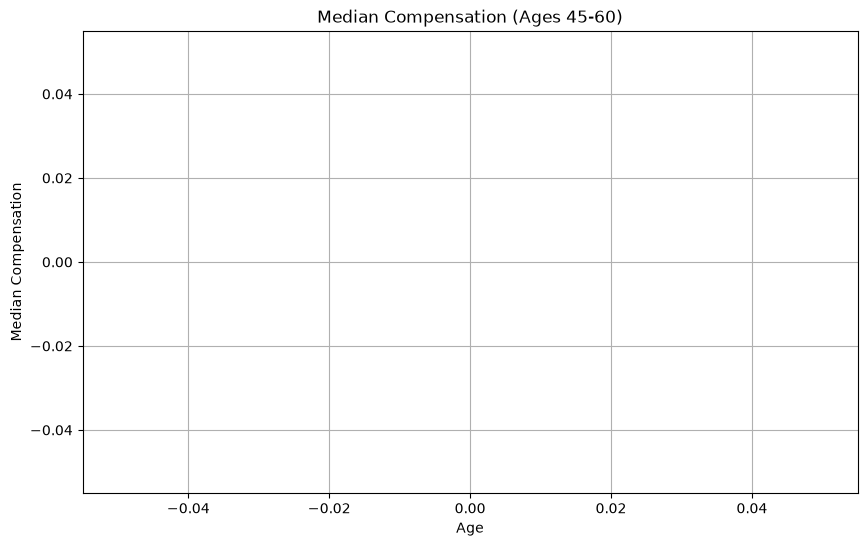

In [31]:
## Write your code here
import pandas as pd
import matplotlib.pyplot as plt

# Load and clean dataset
df = pd.read_csv('survey-data.csv')
df.columns = df.columns.str.strip()

# Convert columns to numeric values safely
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')
df['CompTotal'] = pd.to_numeric(df['CompTotal'], errors='coerce')

# Filter for all ages from 45 to 60, group by Age, find the median
df_45_60 = df[(df['Age'] >= 45) & (df['Age'] <= 60)]
df_line = df_45_60.groupby('Age')['CompTotal'].median()

# Create line chart
df_line.plot(kind='line', marker='o', figsize=(10, 6), title='Median Compensation (Ages 45-60)')
plt.ylabel('Median Compensation')
plt.xlabel('Age')
plt.grid(True)
plt.show()

**Bar Chart**

Create a horizontal bar chart using the `MainBranch` column.


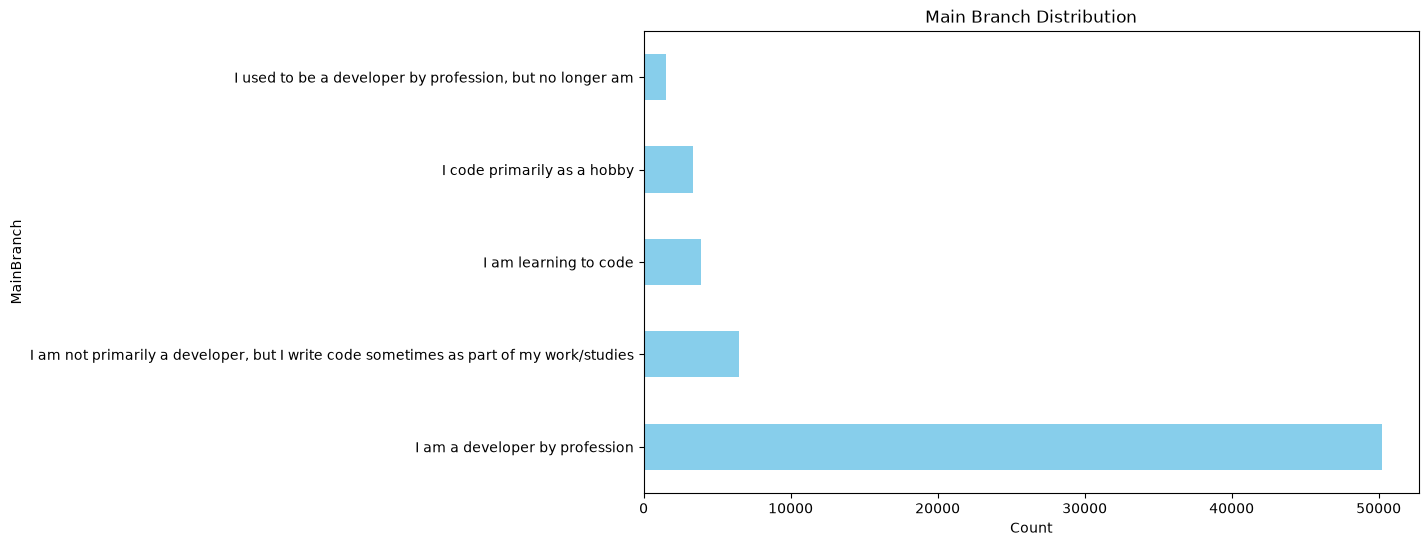

In [32]:
## Write your code here
import pandas as pd
import matplotlib.pyplot as plt

# Load and clean dataset
df = pd.read_csv('survey-data.csv')
df.columns = df.columns.str.strip()

# Create horizontal bar chart of MainBranch distribution
df['MainBranch'].value_counts().plot(kind='barh', figsize=(10, 6), color='skyblue', title='Main Branch Distribution')
plt.xlabel('Count')
plt.show()

### Summary


In this lab, you focused on extracting and visualizing data from an RDBMS using SQL queries and SQLite. You applied various visualization techniques, including:

- Histograms to display the distribution of CompTotal.
- Box plots to show the spread of ages.
- Scatter plots and bubble plots to explore relationships between variables like Age, WorkExp, `TimeSearching` and `TimeAnswering`.
- Pie charts and stacked charts to visualize the composition of data.
- Line charts and bar charts to compare data across categories.


### Close the Database Connection

Once the lab is complete, ensure to close the database connection:


In [ ]:
conn.close()

## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


Copyright © IBM Corporation. All rights reserved.
